In [2]:
import os

base_path = "/kaggle/input/datasets/ashwinialashetty/brain-tumour-mri"
for root, dirs, files in os.walk(base_path):
    level = root.replace(base_path, "").count(os.sep)
    indent = " " * 2 * level
    print(f"{indent}{os.path.basename(root)}/")
    if level < 4:
        for f in files[:3]:
            print(f"{indent}  {f}")
        if len(files) > 3:
            print(f"{indent}  ... ({len(files)} files total)")

brain-tumour-mri/
  Training/
    pituitary/
      Tr-pi_124.jpg
      Tr-pi_949.jpg
      Tr-pi_786.jpg
      ... (1400 files total)
    notumor/
      Tr-no_323.jpg
      Tr-no_86.jpg
      Tr-no_737.jpg
      ... (1400 files total)
    meningioma/
      Tr-me_166.jpg
      Tr-me_1256.jpg
      Tr-me_115.jpg
      ... (1400 files total)
    glioma/
      Tr-gl_1362.jpg
      Tr-gl_821.jpg
      Tr-gl_825.jpg
      ... (1400 files total)
  Testing/
    pituitary/
      Te-pi_307.jpg
      Te-pi_269.jpg
      Te-pi_63.jpg
      ... (400 files total)
    notumor/
      Te-no_39.jpg
      Te-no_46.jpg
      Te-no_340.jpg
      ... (400 files total)
    meningioma/
      Te-me_251.jpg
      Te-me_175.jpg
      Te-me_60.jpg
      ... (400 files total)
    glioma/
      Te-gl_16.jpg
      Te-gl_87.jpg
      Te-gl_392.jpg
      ... (400 files total)


# Step 3: Build manifest (using the dataset’s own Training/Testing split) and train/val split from Training

In [3]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    for f in files:
        if f.endswith(".jpg"):
            print(os.path.join(root, f))
            break

/kaggle/input/datasets/ashwinialashetty/brain-tumour-mri/Training/pituitary/Tr-pi_124.jpg
/kaggle/input/datasets/ashwinialashetty/brain-tumour-mri/Training/notumor/Tr-no_323.jpg
/kaggle/input/datasets/ashwinialashetty/brain-tumour-mri/Training/meningioma/Tr-me_166.jpg
/kaggle/input/datasets/ashwinialashetty/brain-tumour-mri/Training/glioma/Tr-gl_1362.jpg
/kaggle/input/datasets/ashwinialashetty/brain-tumour-mri/Testing/pituitary/Te-pi_307.jpg
/kaggle/input/datasets/ashwinialashetty/brain-tumour-mri/Testing/notumor/Te-no_39.jpg
/kaggle/input/datasets/ashwinialashetty/brain-tumour-mri/Testing/meningioma/Te-me_251.jpg
/kaggle/input/datasets/ashwinialashetty/brain-tumour-mri/Testing/glioma/Te-gl_16.jpg


In [4]:
import os
import glob
import pandas as pd

BASE = "/kaggle/input/datasets/ashwinialashetty/brain-tumour-mri"

classes_to_use = ["glioma", "meningioma", "pituitary"]  # excluding notumor

def build_manifest(split_folder):
    records = []
    for cls in classes_to_use:
        folder = os.path.join(BASE, split_folder, cls)
        files = glob.glob(os.path.join(folder, "*.jpg"))
        for fp in files:
            records.append({"filepath": fp, "class_name": cls})
    return pd.DataFrame(records)

train_val_df = build_manifest("Training")
test_df2 = build_manifest("Testing")

print("Training pool:", train_val_df["class_name"].value_counts().to_dict())
print("Test set:", test_df2["class_name"].value_counts().to_dict())

label_map2 = {"meningioma": 0, "glioma": 1, "pituitary": 2}
train_val_df["label"] = train_val_df["class_name"].map(label_map2)
test_df2["label"] = test_df2["class_name"].map(label_map2)

from sklearn.model_selection import train_test_split
train_df2, val_df2 = train_test_split(
    train_val_df, test_size=0.10, stratify=train_val_df["label"], random_state=42
)


print("\nFinal split:")
print("Train:", len(train_df2), train_df2["class_name"].value_counts().to_dict())
print("Val:  ", len(val_df2), val_df2["class_name"].value_counts().to_dict())
print("Test: ", len(test_df2), test_df2["class_name"].value_counts().to_dict())

Training pool: {'glioma': 1400, 'meningioma': 1400, 'pituitary': 1400}
Test set: {'glioma': 400, 'meningioma': 400, 'pituitary': 400}

Final split:
Train: 3780 {'pituitary': 1260, 'glioma': 1260, 'meningioma': 1260}
Val:   420 {'pituitary': 140, 'meningioma': 140, 'glioma': 140}
Test:  1200 {'glioma': 400, 'meningioma': 400, 'pituitary': 400}


# Step 4: Dataset class for JPGs (simpler than our .mat loader — no HDF5 needed)

In [5]:
import cv2
import numpy as np
import torch
from torch.utils.data import Dataset

class BrainTumorJPGDataset(Dataset):
    def __init__(self, dataframe, img_size=224, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.img_size = img_size
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = cv2.imread(row["filepath"], cv2.IMREAD_GRAYSCALE)
        image = cv2.resize(image, (self.img_size, self.img_size))
        image = np.stack([image, image, image], axis=-1)  # grayscale -> 3-channel

        label = int(row["label"])

        if self.transform:
            image = self.transform(image)
        else:
            image = torch.from_numpy(image).permute(2, 0, 1).float() / 255.0

        return image, label

# Step 5: DataLoaders (reusing the augmentation transforms we already defined)

In [1]:
import torch
import torchvision.transforms as T

IMG_SIZE = 224
BATCH_SIZE = 32

imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std  = [0.229, 0.224, 0.225]

train_transform_aug = T.Compose([
    T.ToPILImage(),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomRotation(degrees=10),
    T.ColorJitter(brightness=0.1, contrast=0.1),
    T.ToTensor(),
    T.Normalize(mean=imagenet_mean, std=imagenet_std),
])

eval_transform = T.Compose([
    T.ToTensor(),
    T.Normalize(mean=imagenet_mean, std=imagenet_std),
])

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cuda


In [6]:
import os, glob, time, random
import numpy as np
import pandas as pd
import cv2
import h5py
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as T
import torchvision.models as models
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, cohen_kappa_score, matthews_corrcoef

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

IMG_SIZE = 224
BATCH_SIZE = 32
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std  = [0.229, 0.224, 0.225]

train_transform_aug = T.Compose([
    T.ToPILImage(),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomRotation(degrees=10),
    T.ColorJitter(brightness=0.1, contrast=0.1),
    T.ToTensor(),
    T.Normalize(mean=imagenet_mean, std=imagenet_std),
])
eval_transform = T.Compose([
    T.ToTensor(),
    T.Normalize(mean=imagenet_mean, std=imagenet_std),
])

# ---------- SSPANet ----------
class ChannelAttention(nn.Module):
    def __init__(self, in_channels, reduction_kernel=1):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        self.conv = nn.Conv2d(2, 1, kernel_size=reduction_kernel, padding=reduction_kernel // 2, bias=False)
        self.bn = nn.BatchNorm2d(1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg = self.avg_pool(x).squeeze(-1).squeeze(-1)
        mx = self.max_pool(x).squeeze(-1).squeeze(-1)
        z = torch.stack([avg, mx], dim=1).unsqueeze(-1)
        f1 = self.bn(self.conv(z))
        m_c = self.sigmoid(f1).squeeze(1).squeeze(-1)
        return m_c.view(m_c.size(0), m_c.size(1), 1, 1)


class StripAttention(nn.Module):
    def __init__(self, in_channels):
        super().__init__()
        self.pool_h = nn.AdaptiveAvgPool2d((None, 1))
        self.pool_w = nn.AdaptiveAvgPool2d((1, None))
        self.conv = nn.Conv2d(in_channels, in_channels, kernel_size=1, bias=False)

    def forward(self, x):
        b, c, h, w = x.shape
        s_h = self.pool_h(x).expand(-1, -1, -1, w)
        s_v = self.pool_w(x).expand(-1, -1, h, -1)
        return self.conv(s_h + s_v)


class StyleAttention(nn.Module):
    def __init__(self, in_channels):
        super().__init__()
        self.conv = nn.Conv2d(2, in_channels, kernel_size=1, bias=False)

    def forward(self, x):
        mu = x.mean(dim=1, keepdim=True)
        sigma = x.std(dim=1, keepdim=True, unbiased=False)
        return self.conv(torch.cat([mu, sigma], dim=1))


class SpatialAttention(nn.Module):
    def __init__(self, in_channels, use_strip=True, use_style=True):
        super().__init__()
        assert use_strip or use_style
        self.use_strip, self.use_style = use_strip, use_style
        if use_strip: self.strip = StripAttention(in_channels)
        if use_style: self.style = StyleAttention(in_channels)
        self.fuse_conv = nn.Conv2d(in_channels, 1, kernel_size=1, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        if self.use_strip and self.use_style:
            fused = self.strip(x) + self.style(x)
        elif self.use_strip:
            fused = self.strip(x)
        else:
            fused = self.style(x)
        return self.sigmoid(self.fuse_conv(fused))


class SSPANet(nn.Module):
    def __init__(self, in_channels, use_channel=True, use_strip=True, use_style=True, residual=True):
        super().__init__()
        self.use_channel = use_channel
        self.residual = residual
        if use_channel:
            self.channel_attn = ChannelAttention(in_channels)
        self.use_spatial = use_strip or use_style
        if self.use_spatial:
            self.spatial_attn = SpatialAttention(in_channels, use_strip, use_style)

    def forward(self, x):
        out = x
        if self.use_channel:
            out = out * self.channel_attn(out)
        if self.use_spatial:
            out = out * self.spatial_attn(out)
        if self.residual:
            out = out + x
        return out


class ResNetSSPANet(nn.Module):
    def __init__(self, num_classes=3, use_channel=True, use_strip=True, use_style=True, pretrained=True):
        super().__init__()
        resnet = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None)
        self.stem = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu, resnet.maxpool)
        self.layer1 = resnet.layer1
        self.layer2 = resnet.layer2
        self.layer3 = resnet.layer3
        self.layer4 = resnet.layer4

        attn_kwargs = dict(use_channel=use_channel, use_strip=use_strip, use_style=use_style)
        self.attn1 = SSPANet(256,  **attn_kwargs)
        self.attn2 = SSPANet(512,  **attn_kwargs)
        self.attn3 = SSPANet(1024, **attn_kwargs)
        self.attn4 = SSPANet(2048, **attn_kwargs)

        self.avgpool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(2048, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.attn1(self.layer1(x))
        x = self.attn2(self.layer2(x))
        x = self.attn3(self.layer3(x))
        x = self.attn4(self.layer4(x))
        x = self.avgpool(x).flatten(1)
        return self.fc(x)


# ---------- Training / Eval ----------
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def evaluate(model, loader, device):
    model.eval()
    all_preds, all_labels = [], []
    total_loss = 0.0
    criterion = nn.CrossEntropyLoss()
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            total_loss += loss.item() * images.size(0)
            preds = outputs.argmax(dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    avg_loss = total_loss / len(loader.dataset)
    acc = accuracy_score(all_labels, all_preds)
    precision, recall, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average="macro", zero_division=0)
    kappa = cohen_kappa_score(all_labels, all_preds)
    mcc = matthews_corrcoef(all_labels, all_preds)
    return {"loss": avg_loss, "accuracy": acc, "precision": precision, "recall": recall, "f1": f1, "kappa": kappa, "mcc": mcc}


from torch.cuda.amp import autocast, GradScaler

def train_model_fast(model, train_loader, val_loader, device, epochs=20, lr=0.0001, patience=7, model_name="model"):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    scaler = GradScaler()
    best_val_loss = float("inf")
    patience_counter = 0

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        all_preds, all_labels = [], []
        t0 = time.time()

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            with autocast():
                outputs = model(images)
                loss = criterion(outputs, labels)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item() * images.size(0)
            preds = outputs.argmax(dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

        train_loss = running_loss / len(train_loader.dataset)
        train_acc = accuracy_score(all_labels, all_preds)
        val_metrics = evaluate(model, val_loader, device)
        elapsed = time.time() - t0
        print(f"[{model_name}] Epoch {epoch+1}/{epochs} | train_loss={train_loss:.4f} train_acc={train_acc:.4f} | val_loss={val_metrics['loss']:.4f} val_acc={val_metrics['accuracy']:.4f} | {elapsed:.1f}s")

        if val_metrics["loss"] < best_val_loss:
            best_val_loss = val_metrics["loss"]
            patience_counter = 0
            torch.save(model.state_dict(), f"/kaggle/working/{model_name}_best.pt")
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"Early stopping at epoch {epoch+1}")
                break

    model.load_state_dict(torch.load(f"/kaggle/working/{model_name}_best.pt"))
    return model


# ---------- Second dataset manifest + loaders ----------
BASE = "/kaggle/input/datasets/ashwinialashetty/brain-tumour-mri"
classes_to_use = ["glioma", "meningioma", "pituitary"]

def build_manifest(split_folder):
    records = []
    for cls in classes_to_use:
        folder = os.path.join(BASE, split_folder, cls)
        files = glob.glob(os.path.join(folder, "*.jpg"))
        for fp in files:
            records.append({"filepath": fp, "class_name": cls})
    return pd.DataFrame(records)

train_val_df = build_manifest("Training")
test_df2 = build_manifest("Testing")

label_map2 = {"meningioma": 0, "glioma": 1, "pituitary": 2}
train_val_df["label"] = train_val_df["class_name"].map(label_map2)
test_df2["label"] = test_df2["class_name"].map(label_map2)

train_df2, val_df2 = train_test_split(train_val_df, test_size=0.10, stratify=train_val_df["label"], random_state=42)

class BrainTumorJPGDataset(Dataset):
    def __init__(self, dataframe, img_size=224, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.img_size = img_size
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = cv2.imread(row["filepath"], cv2.IMREAD_GRAYSCALE)
        image = cv2.resize(image, (self.img_size, self.img_size))
        image = np.stack([image, image, image], axis=-1)
        label = int(row["label"])
        if self.transform:
            image = self.transform(image)
        else:
            image = torch.from_numpy(image).permute(2, 0, 1).float() / 255.0
        return image, label

train_ds2 = BrainTumorJPGDataset(train_df2, img_size=IMG_SIZE, transform=train_transform_aug)
val_ds2   = BrainTumorJPGDataset(val_df2,   img_size=IMG_SIZE, transform=eval_transform)
test_ds2  = BrainTumorJPGDataset(test_df2,  img_size=IMG_SIZE, transform=eval_transform)

train_loader2 = DataLoader(train_ds2, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)
val_loader2   = DataLoader(val_ds2,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader2  = DataLoader(test_ds2,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Train: {len(train_df2)}, Val: {len(val_df2)}, Test: {len(test_df2)}")
print(f"Train batches: {len(train_loader2)}, Val batches: {len(val_loader2)}, Test batches: {len(test_loader2)}")

images2, labels2 = next(iter(train_loader2))
print("Batch image shape:", images2.shape)
print("Unique labels:", labels2.unique())

Device: cuda
Train: 3780, Val: 420, Test: 1200
Train batches: 119, Val batches: 14, Test batches: 38
Batch image shape: torch.Size([32, 3, 224, 224])
Unique labels: tensor([0, 1, 2])


# Step 6: Train channel-only SSPANet (our ablation winner) from scratch on this new dataset

In [7]:
set_seed(42)
model_gen = ResNetSSPANet(num_classes=3, use_channel=True, use_strip=False, use_style=False).to(device)

model_gen = train_model_fast(
    model_gen, train_loader2, val_loader2, device,
    epochs=20, lr=0.0001, patience=7, model_name="generalization_channel_only"
)

test_metrics_gen = evaluate(model_gen, test_loader2, device)
print("\nTest set results (channel-only SSPANet, independent dataset):")
for k, v in test_metrics_gen.items():
    print(f"  {k}: {v:.4f}")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 222MB/s]
/tmp/ipykernel_49/1836557638.py:187: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
/tmp/ipykernel_49/1836557638.py:200: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


[generalization_channel_only] Epoch 1/20 | train_loss=0.3826 train_acc=0.8484 | val_loss=0.1979 val_acc=0.9286 | 25.4s


/tmp/ipykernel_49/1836557638.py:200: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


[generalization_channel_only] Epoch 2/20 | train_loss=0.1083 train_acc=0.9648 | val_loss=0.0604 val_acc=0.9810 | 19.2s


...

[generalization_channel_only] Epoch 17/20 | train_loss=0.0110 train_acc=0.9968 | val_loss=0.0082 val_acc=0.9976 | 20.0s


/tmp/ipykernel_49/1836557638.py:200: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


[generalization_channel_only] Epoch 18/20 | train_loss=0.0084 train_acc=0.9968 | val_loss=0.0190 val_acc=0.9952 | 20.0s


/tmp/ipykernel_49/1836557638.py:200: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


[generalization_channel_only] Epoch 19/20 | train_loss=0.0209 train_acc=0.9923 | val_loss=0.0369 val_acc=0.9881 | 20.1s
Early stopping at epoch 19

Test set results (channel-only SSPANet, independent dataset):
  loss: 0.7882
  accuracy: 0.9400
  precision: 0.9476
  recall: 0.9400
  f1: 0.9397
  kappa: 0.9100
  mcc: 0.9140


# Step 7: Train full SSPANet on the same new dataset for comparison

In [8]:
set_seed(42)
model_gen_full = ResNetSSPANet(num_classes=3, use_channel=True, use_strip=True, use_style=True).to(device)

model_gen_full = train_model_fast(
    model_gen_full, train_loader2, val_loader2, device,
    epochs=20, lr=0.0001, patience=7, model_name="generalization_full_sspanet"
)

test_metrics_gen_full = evaluate(model_gen_full, test_loader2, device)
print("\nTest set results (full SSPANet, independent dataset):")
for k, v in test_metrics_gen_full.items():
    print(f"  {k}: {v:.4f}")

/tmp/ipykernel_49/1836557638.py:187: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
/tmp/ipykernel_49/1836557638.py:200: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


[generalization_full_sspanet] Epoch 1/20 | train_loss=0.3537 train_acc=0.8709 | val_loss=0.1472 val_acc=0.9524 | 29.7s


/tmp/ipykernel_49/1836557638.py:200: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


[generalization_full_sspanet] Epoch 2/20 | train_loss=0.1126 train_acc=0.9585 | val_loss=0.0380 val_acc=0.9952 | 29.1s


/tmp/ipykernel_49/1836557638.py:200: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


...

[generalization_full_sspanet] Epoch 9/20 | train_loss=0.0181 train_acc=0.9934 | val_loss=0.0453 val_acc=0.9905 | 28.7s


/tmp/ipykernel_49/1836557638.py:200: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


[generalization_full_sspanet] Epoch 10/20 | train_loss=0.0442 train_acc=0.9862 | val_loss=0.0617 val_acc=0.9810 | 28.7s


/tmp/ipykernel_49/1836557638.py:200: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


[generalization_full_sspanet] Epoch 11/20 | train_loss=0.0191 train_acc=0.9937 | val_loss=0.0438 val_acc=0.9952 | 28.7s
Early stopping at epoch 11

Test set results (full SSPANet, independent dataset):
  loss: 0.3475
  accuracy: 0.9358
  precision: 0.9407
  recall: 0.9358
  f1: 0.9350
  kappa: 0.9038
  mcc: 0.9067


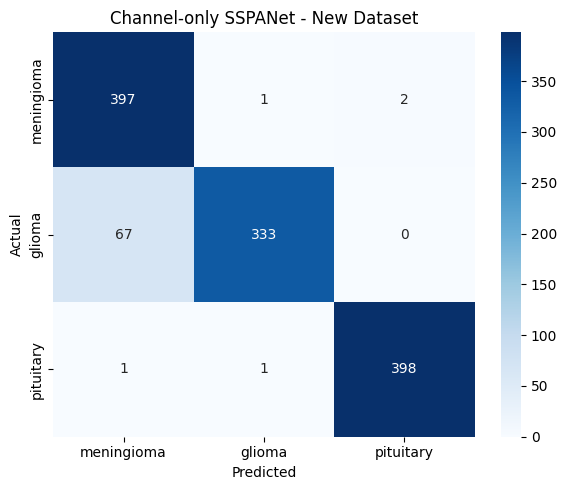

              precision    recall  f1-score   support

  meningioma       0.85      0.99      0.92       400
      glioma       0.99      0.83      0.91       400
   pituitary       0.99      0.99      0.99       400

    accuracy                           0.94      1200
   macro avg       0.95      0.94      0.94      1200
weighted avg       0.95      0.94      0.94      1200



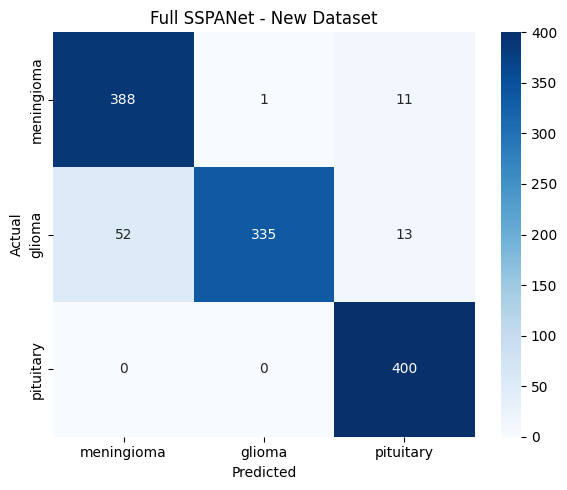

              precision    recall  f1-score   support

  meningioma       0.88      0.97      0.92       400
      glioma       1.00      0.84      0.91       400
   pituitary       0.94      1.00      0.97       400

    accuracy                           0.94      1200
   macro avg       0.94      0.94      0.94      1200
weighted avg       0.94      0.94      0.94      1200



In [10]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

class_names = ["meningioma", "glioma", "pituitary"]

def get_predictions(model, loader, device):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            outputs = model(images)
            preds = outputs.argmax(dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())
    return all_preds, all_labels

def plot_confusion_matrix(preds, labels, class_names, title):
    cm = confusion_matrix(labels, preds)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(title)
    plt.tight_layout()
    plt.savefig(f"/kaggle/working/{title.replace(' ', '_')}.png", dpi=150, bbox_inches='tight')
    plt.show()

# Channel-only (best ablation config)
preds_gen, labels_gen = get_predictions(model_gen, test_loader2, device)
plot_confusion_matrix(preds_gen, labels_gen, class_names, "Channel-only SSPANet - New Dataset")

print(classification_report(labels_gen, preds_gen, target_names=class_names))

# Full SSPANet (for comparison)
preds_gen_full, labels_gen_full = get_predictions(model_gen_full, test_loader2, device)
plot_confusion_matrix(preds_gen_full, labels_gen_full, class_names, "Full SSPANet - New Dataset")
print(classification_report(labels_gen_full, preds_gen_full, target_names=class_names))

# GradCAM on the channel-only model (our best performer)

In [12]:
!pip install grad-cam -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 1.6 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


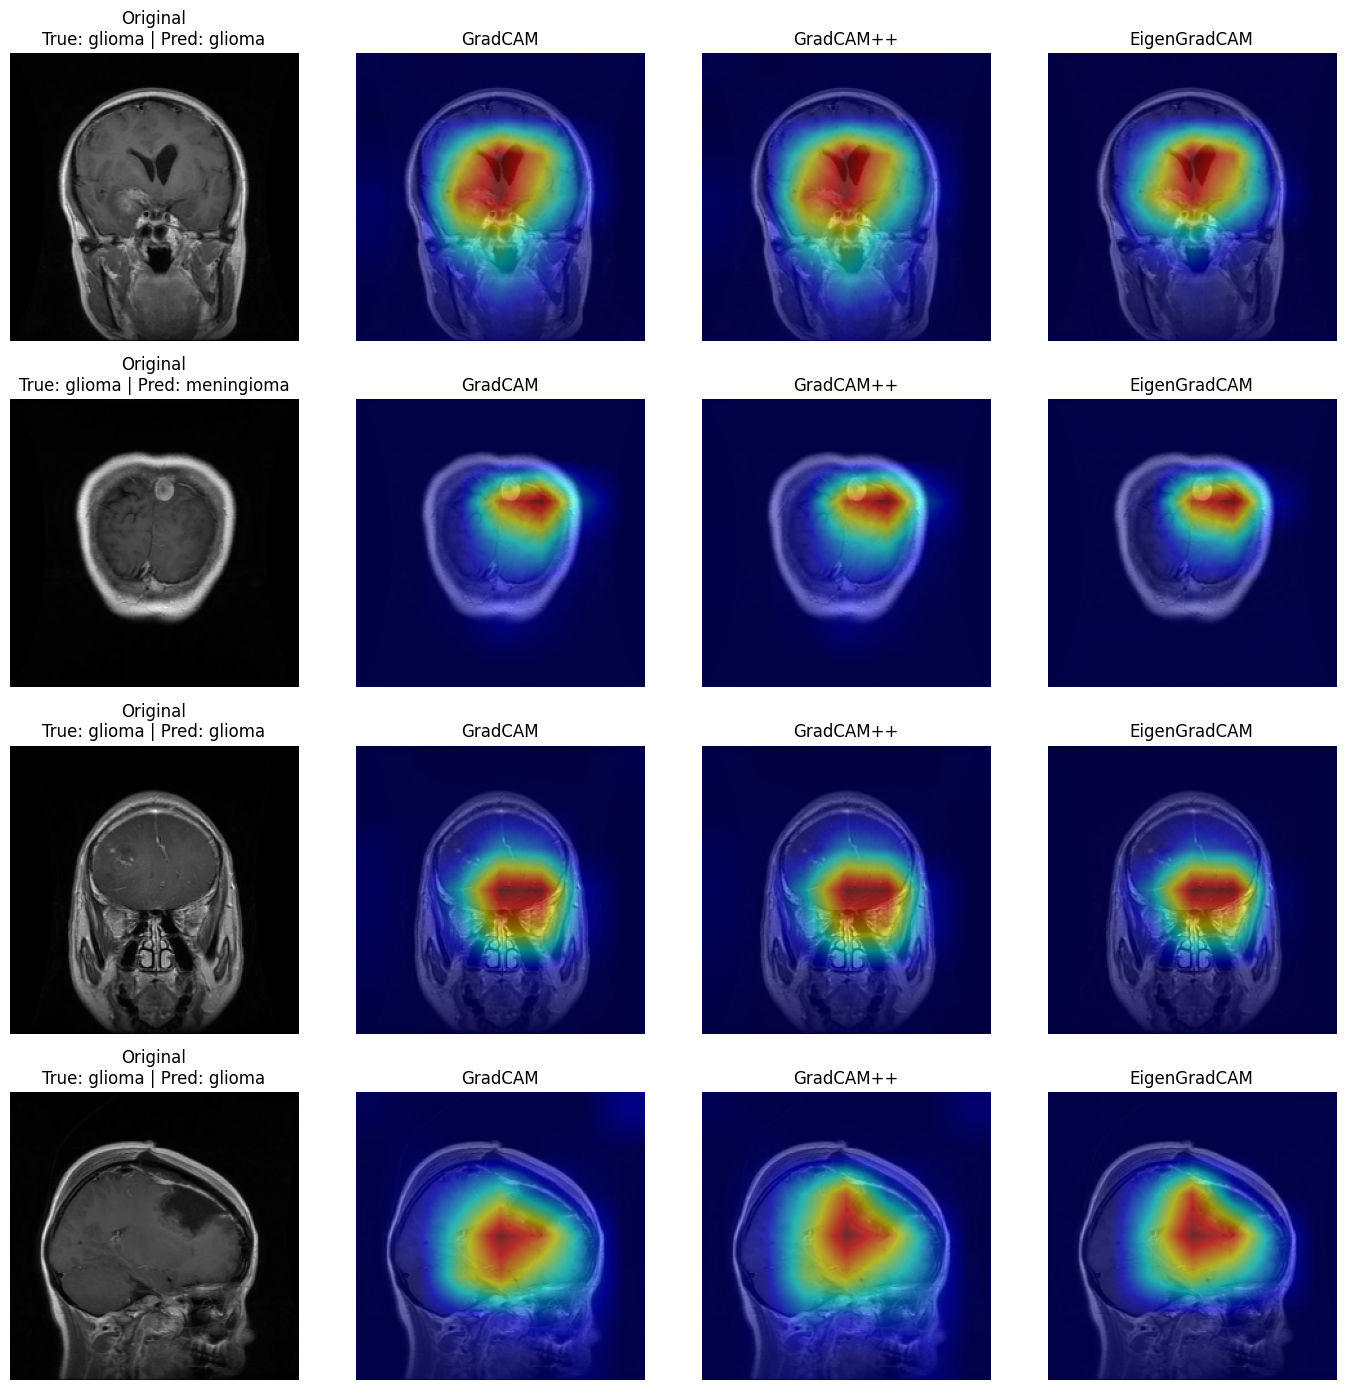

In [13]:
from pytorch_grad_cam import GradCAM, GradCAMPlusPlus, EigenGradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

model_gen.eval()
target_layers = [model_gen.attn4]

def denormalize_for_display(img_tensor):
    mean = torch.tensor(imagenet_mean).view(3, 1, 1)
    std = torch.tensor(imagenet_std).view(3, 1, 1)
    img = (img_tensor.cpu() * std + mean).clamp(0, 1)
    return img.permute(1, 2, 0).numpy()

images_g, labels_g = next(iter(test_loader2))
images_g = images_g.to(device)

n_samples = 4
fig, axes = plt.subplots(n_samples, 4, figsize=(14, 3.5 * n_samples))

cam_methods = {
    "GradCAM": GradCAM,
    "GradCAM++": GradCAMPlusPlus,
    "EigenGradCAM": EigenGradCAM,
}

for i in range(n_samples):
    input_tensor = images_g[i:i+1]
    rgb_img = denormalize_for_display(images_g[i])
    true_label = class_names[labels_g[i].item()]

    with torch.no_grad():
        pred = model_gen(input_tensor).argmax(dim=1).item()

    pred_label = class_names[pred]

    axes[i, 0].imshow(rgb_img)
    axes[i, 0].set_title(f"Original\nTrue: {true_label} | Pred: {pred_label}")
    axes[i, 0].axis("off")

    for j, (name, CamClass) in enumerate(cam_methods.items()):
        cam = CamClass(model=model_gen, target_layers=target_layers)
        targets = [ClassifierOutputTarget(pred)]
        grayscale_cam = cam(input_tensor=input_tensor, targets=targets)[0]
        visualization = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)
        axes[i, j+1].imshow(visualization)
        axes[i, j+1].set_title(name)
        axes[i, j+1].axis("off")

plt.tight_layout()
plt.savefig("/kaggle/working/gradcam_new_dataset.png", dpi=150, bbox_inches='tight')
plt.show()

In [14]:
print(confusion_matrix(labels_gen, preds_gen))

[[397   1   2]
 [ 67 333   0]
 [  1   1 398]]


In [15]:
print(confusion_matrix(labels_gen_full, preds_gen_full))
print(classification_report(labels_gen_full, preds_gen_full, target_names=class_names))

[[388   1  11]
 [ 52 335  13]
 [  0   0 400]]
              precision    recall  f1-score   support

  meningioma       0.88      0.97      0.92       400
      glioma       1.00      0.84      0.91       400
   pituitary       0.94      1.00      0.97       400

    accuracy                           0.94      1200
   macro avg       0.94      0.94      0.94      1200
weighted avg       0.94      0.94      0.94      1200

